# 🧠 Bayes, ridge and lasso, with your 5K
[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/didilelass/didilelass/blob/main/run-ml/learn_bayes_ridge_lasso.ipynb)

A hands-on refresher. Each part has **one idea to remember**, a bit of math, code you can change, and an exercise (answers are hidden under ▶).

| Part | Idea |
|---|---|
| 1 | **Bayes:** start with a belief, update it with evidence |
| 2 | **Bayesian linear regression:** the same, for regression weights, with an exact formula |
| 3 | **Ridge = Bayes with a Gaussian prior at 0.** Derive it on paper once |
| 4 | **Lasso = Laplace prior:** some weights become exactly 0 |
| 5 | **Prior strength = λ:** play with it |

Run the cells top to bottom (`Shift + Enter`).

In [1]:
# In Colab: download the code. Locally: use the repo you're already in.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("runml"):
    !git clone -q --depth 1 https://github.com/didilelass/didilelass.git
    %cd didilelass/run-ml

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from runml.data import load_runs
from runml.features import build_dataset, FEATURES

# Chart style: quiet axes, thin lines, colors by job.
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#a3a29c"
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#d6d5d0",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#ecebe7", "grid.linewidth": 0.8, "lines.linewidth": 2,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
rng = np.random.default_rng(0)

## Part 1: Bayes' rule

> 🧠 **Remember:** *new belief = old belief × how well it explains what I just saw* (then rescale).

$$P(A\mid B) = \frac{P(B\mid A)\,P(A)}{P(B)} \qquad\Longrightarrow\qquad \underbrace{P(w\mid D)}_{\text{posterior}} \;\propto\; \underbrace{P(D\mid w)}_{\text{likelihood}}\;\underbrace{P(w)}_{\text{prior}}$$

**Example:** how many seconds does one extra hour of sleep save you on a 5K? Call it $w$.
- **Prior:** for most runners, about 8 s, but you're unsure: $w \sim \mathcal N(8,\ 12^2)$
- **Data:** each 5K tells you (noisily) your own effect. Here we pretend the truth is **15 s** per hour.

When both prior and noise are Gaussian, the update has a simple formula:

$$\text{precision}_{new} = \text{precision}_{old} + \frac{x^2}{\sigma^2}, \qquad \text{mean}_{new} = \frac{\text{precision}_{old}\cdot\text{mean}_{old} + x\,y/\sigma^2}{\text{precision}_{new}}$$

(*precision* = 1 / variance = how sure you are. **Precisions add up.** That's the whole trick.)

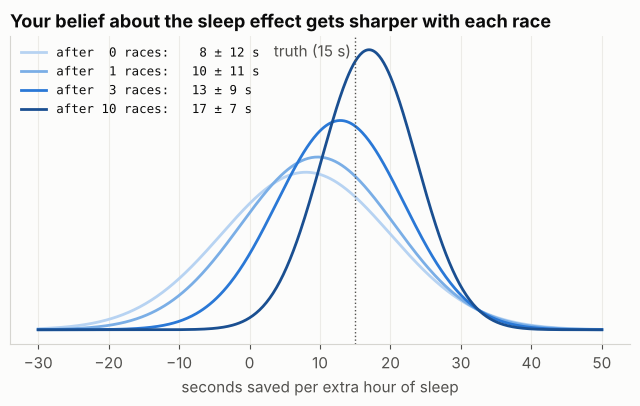

In [3]:
TRUE_EFFECT = 15      # seconds per hour of sleep (unknown to the model)
NOISE = 40            # a 5K varies about ±40 s day to day
prior_mean, prior_sd = 8, 12

rng = np.random.default_rng(5)
# Simulate 10 races: hours of sleep above/below your normal, and the time saved.
sleep_diff = rng.choice([-2, -1.5, -1, 1, 1.5, 2], size=10)
time_saved = TRUE_EFFECT * sleep_diff + rng.normal(0, NOISE, size=10)

def posterior(n):
    prec = 1 / prior_sd**2 + np.sum(sleep_diff[:n]**2) / NOISE**2
    mean = (prior_mean / prior_sd**2 + np.sum(sleep_diff[:n] * time_saved[:n]) / NOISE**2) / prec
    return mean, np.sqrt(1 / prec)

w = np.linspace(-30, 50, 500)
fig, ax = plt.subplots(figsize=(8, 4))
shades = ["#b7d3f2", "#7aaee6", "#2a78d6", "#1a4f91"]  # one hue, light -> dark = more data
for n, c in zip([0, 1, 3, 10], shades):
    m, s = posterior(n)
    y = stats.norm.pdf(w, m, s)
    ax.plot(w, y, color=c, label=f"after {n:>2} races: {m:4.0f} ± {s:.0f} s")
ax.axvline(TRUE_EFFECT, color=INK2, linestyle=":", linewidth=1)
ax.text(TRUE_EFFECT, ax.get_ylim()[1] * 0.98, "truth (15 s) ", color=INK2, va="top", ha="right")
ax.legend(loc="upper left", frameon=False, prop={"family": "monospace", "size": 9})
ax.set(title="Your belief about the sleep effect gets sharper with each race",
       xlabel="seconds saved per extra hour of sleep", yticks=[])
plt.show()

**What to notice:** with 0 races the curve is the prior (wide, centred on 8). Each race moves it toward the truth **and** makes it narrower.

**✏️ Exercise 1.** Set `prior_sd = 1` (very confident prior) and rerun. Then set `prior_sd = 100`. What changes?

<details><summary>▶ Answer</summary>

`prior_sd = 1`: the curve barely moves from 8, even after 10 races, because a strong prior needs lots of evidence. `prior_sd = 100`: the prior is almost ignored, and the result is basically what the data alone say (plain least squares). **The prior's strength decides how much data it takes to change your mind.**
</details>

## Part 2: Bayesian linear regression

> 🧠 **Remember:** same idea, but $w$ is a vector of weights. **Gaussian prior + Gaussian noise ⇒ Gaussian posterior, with an exact formula.**

Model: $y = Xw + \varepsilon,\ \ \varepsilon\sim\mathcal N(0,\sigma^2 I)$. Prior: $w \sim \mathcal N(\mu_0, \Sigma_0)$.

$$\boxed{\Sigma_n = \left(\Sigma_0^{-1} + \tfrac{1}{\sigma^2}X^\top X\right)^{-1} \qquad \mu_n = \Sigma_n\left(\Sigma_0^{-1}\mu_0 + \tfrac{1}{\sigma^2}X^\top y\right)}$$

Read it as **Part 1 in matrix form:** precision (inverse covariance) = prior precision + data precision.

Prediction for a new day $x_*$: mean $\mu_n^\top x_*$, variance $\sigma^2 + x_*^\top \Sigma_n x_*$ (the "likely between" range in the app).

Let's fit it on the sample run log (29 races and tempo runs; target = 5K-equivalent time in seconds).

In [4]:
runs = load_runs("data/sample_runs.csv")
data = build_dataset(runs)
X_raw = data[FEATURES]
y = data["target_5k_min"].to_numpy() * 60   # seconds

# Standardise features (mean 0, sd 1) and centre y: then all weights are comparable
# and we don't need an intercept.
X = ((X_raw - X_raw.mean()) / X_raw.std()).to_numpy()
y_c = y - y.mean()
print(f"{X.shape[0]} examples, {X.shape[1]} features")
data[["date", "target_5k_min"] + FEATURES[:4]].head()

29 examples, 11 features


,date,target_5k_min,fitness,fatigue,freshness,km_per_week
0,2026-04-02,31.380000,28.907007,17.972905,10.934102,11.8500
1,2026-04-09,34.777017,28.651251,22.510952,6.140299,12.3550
2,2026-04-16,30.860000,28.012836,23.035613,4.977223,15.2475
3,2026-04-23,33.889611,26.411118,18.251762,8.159355,15.4175
4,2026-04-30,30.010000,25.671836,20.232330,5.439507,15.6925


In [5]:
def bayes_linreg(X, y, mu0, Sigma0, sigma):
    P0 = np.linalg.inv(Sigma0)                      # prior precision
    Sn = np.linalg.inv(P0 + X.T @ X / sigma**2)     # posterior covariance
    mun = Sn @ (P0 @ mu0 + X.T @ y / sigma**2)      # posterior mean
    return mun, Sn

sigma, tau = 40.0, 20.0                    # noise sd, prior sd for each weight (seconds)
d = X.shape[1]
mu_n, S_n = bayes_linreg(X, y_c, np.zeros(d), tau**2 * np.eye(d), sigma)

result = pd.DataFrame({"weight (s per 1 sd)": mu_n, "± (1 sd)": np.sqrt(np.diag(S_n))},
                      index=FEATURES).round(1)
result.sort_values("weight (s per 1 sd)")

,weight (s per 1 sd),± (1 sd)
is_race,-61.5,7.5
longest_run_km,-14.9,16.4
km_per_week,-8.8,17.5
fitness,-8.6,15.7
km_last_7d,-7.3,16.1
freshness,-5.1,13.1
fatigue,-2.8,18.1
runs_per_week,-0.9,14.7
days_since_run,2.3,8.2
hard_per_week,11.1,12.5


Every weight now comes **with its own uncertainty**. A weight like −20 ± 5 is clearly real. One like 3 ± 15 means "the data can't tell".

**✏️ Exercise 2.** Predict the 5K for the *last* row of data, with a range. Use `mu_n`, `S_n`, `sigma` and `y.mean()`.

<details><summary>▶ Answer</summary>

```python
x = X[-1]
mean = y.mean() + mu_n @ x
sd = np.sqrt(sigma**2 + x @ S_n @ x)
print(f"{mean/60:.2f} min ± {sd:.0f} s   (actual {y[-1]/60:.2f})")
```
</details>

## Part 3: Ridge is Bayes with a Gaussian prior at 0

> 🧠 **Remember:** *ridge = "keep weights small" = Gaussian prior centred on 0.* **λ = σ² / τ²** (noise ÷ prior width).

**Derive it once on paper** (5 lines). Minimise

$$L(w) = \lVert y - Xw\rVert^2 + \lambda \lVert w\rVert^2$$

1. Expand: $L = y^\top y - 2w^\top X^\top y + w^\top X^\top X w + \lambda w^\top w$
2. Gradient: $\nabla L = -2X^\top y + 2X^\top X w + 2\lambda w$
3. Set to 0: $(X^\top X + \lambda I)\,w = X^\top y$
4. $\boxed{w_{ridge} = (X^\top X + \lambda I)^{-1} X^\top y}$
5. Compare with $\mu_n$ above when $\mu_0 = 0$, $\Sigma_0=\tau^2 I$: multiply through by $\sigma^2$ and you get the same thing with $\lambda = \sigma^2/\tau^2$. ✅

**Why:** $-\log(\text{posterior}) = \frac{1}{2\sigma^2}\lVert y-Xw\rVert^2 + \frac{1}{2\tau^2}\lVert w\rVert^2 + \text{const}$. Minimising that is ridge. So **ridge gives the peak of the posterior (MAP)**; Bayes also gives the width.

Check it numerically:

In [6]:
from sklearn.linear_model import Ridge

lam = sigma**2 / tau**2
w_formula = np.linalg.solve(X.T @ X + lam * np.eye(d), X.T @ y_c)
w_sklearn = Ridge(alpha=lam, fit_intercept=False).fit(X, y_c).coef_

print("lambda =", lam)
print("closed form == sklearn Ridge:", np.allclose(w_formula, w_sklearn))
print("ridge     == Bayesian mean: ", np.allclose(w_formula, mu_n))

lambda = 4.0
closed form == sklearn Ridge: True
ridge     == Bayesian mean:  True


## Part 4: Lasso, the Laplace prior that picks features

> 🧠 **Remember:** *Ridge **shrinks** all weights a bit. Lasso **kills** some, setting them to exactly 0.* Squares (L2) vs absolute values (L1). Circle vs diamond.

| | Prior | Penalty | Weights |
|---|---|---|---|
| Ridge | Gaussian $e^{-w^2/2\tau^2}$ (smooth top) | $\lambda\sum w_j^2$ | small, never exactly 0 |
| Lasso | Laplace $e^{-\lvert w\rvert/b}$ (sharp peak at 0) | $\lambda\sum \lvert w_j\rvert$ | many exactly 0 |

**Why exactly 0?** The penalty $\lvert w\rvert$ has a corner at 0, and the optimum likes to sit in that corner. The L1 "budget" region is a diamond whose corners lie on the axes, where some weights are 0. (Lasso has no closed form because of that corner; it's solved iteratively, e.g. coordinate descent.)

Watch the weights as the penalty grows:

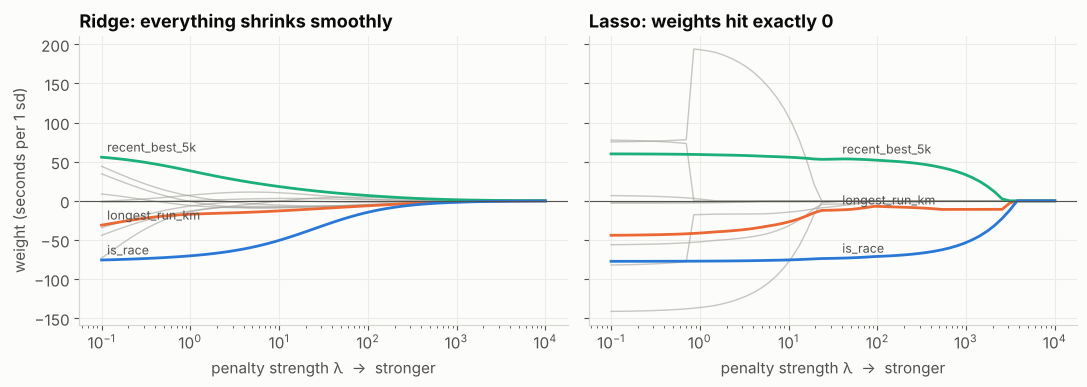

Features kept by lasso, weak → strong penalty: [11 11  9  7  4  3]


In [7]:
from sklearn.linear_model import Lasso

import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)  # tiny penalties converge slowly; harmless here

alphas = np.logspace(-1, 4, 60)
ridge_path = np.array([Ridge(alpha=a, fit_intercept=False).fit(X, y_c).coef_ for a in alphas])
# sklearn's Lasso minimises (1/2n)·error + alpha·|w|, so alpha = λ / 2n puts it on our scale.
lasso_path = np.array([Lasso(alpha=a / (2 * len(y_c)), fit_intercept=False, max_iter=50_000)
                       .fit(X, y_c).coef_ for a in alphas])

# Highlight the 3 features lasso keeps the longest as the penalty grows.
last_alive = [(np.abs(lasso_path[:, j]) > 1e-6).nonzero()[0].max(initial=-1) for j in range(d)]
top = np.argsort(last_alive)[::-1][:3]
colors = dict(zip(top, [BLUE, ORANGE, AQUA]))
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, path, name in [(axes[0], ridge_path, "Ridge: everything shrinks smoothly"),
                       (axes[1], lasso_path, "Lasso: weights hit exactly 0")]:
    for j in range(d):
        hl = j in colors
        ax.plot(alphas, path[:, j], color=colors.get(j, GRAY), lw=2 if hl else 1, alpha=1 if hl else .6)
        if hl:
            k = 0 if path is ridge_path else 30  # label where the lines are spread apart
            ax.annotate(FEATURES[j], (alphas[k], path[k, j]), xytext=(4, 4),
                        textcoords="offset points", color=INK2, fontsize=9)
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set(xscale="log", title=name, xlabel="penalty strength λ  →  stronger")
axes[0].set_ylabel("weight (seconds per 1 sd)")
plt.tight_layout(); plt.show()

nonzero = (np.abs(lasso_path) > 1e-6).sum(axis=1)
print("Features kept by lasso, weak → strong penalty:", nonzero[::10])

**What to notice:** in the lasso chart, lines drop to **exactly 0** one by one. The 3 coloured features survive the longest: those are the ones lasso thinks matter most. The wild gray line on the right is a classic lasso weakness: when features are **correlated** (fitness, km per week, km in the last 7 days all measure "how much you run"), lasso arbitrarily hands the weight from one to another. Ridge shares it smoothly. **Elastic net** (L1 + L2) fixes this.

**✏️ Exercise 3.** Use `LassoCV` and `RidgeCV` to choose λ by cross-validation. Which features does lasso keep?

<details><summary>▶ Answer</summary>

```python
from sklearn.linear_model import LassoCV, RidgeCV
lasso = LassoCV(cv=5, fit_intercept=False).fit(X, y_c)
ridge = RidgeCV(alphas=np.logspace(-2, 4, 50), fit_intercept=False).fit(X, y_c)
print("kept by lasso:", [f for f, c in zip(FEATURES, lasso.coef_) if abs(c) > 1e-6])
```
(With only 29 rows, plain `cv=5` mixes past and future. For honest time-series scoring use `TimeSeriesSplit`, as `runml/model.py` does.)
</details>

**When to use which?**
- **Ridge:** many features that all matter a bit, or correlated features (it shares weight between them)
- **Lasso:** you suspect only a few matter, or you want a simple model you can explain
- **Elastic net:** a mix of both (L1 + L2), good when features are correlated *and* you want selection
- **Bayesian:** little data, prior knowledge, or you need uncertainty (like the app)

## Part 5: Prior strength is λ. Play with it.

> 🧠 **Remember:** *Strong prior = big λ = small weights = simple model (risk: underfit). Weak prior = small λ = data rules (risk: overfit).* This is the **bias–variance trade-off**.

Below: training error vs error on *future* runs, as λ changes.

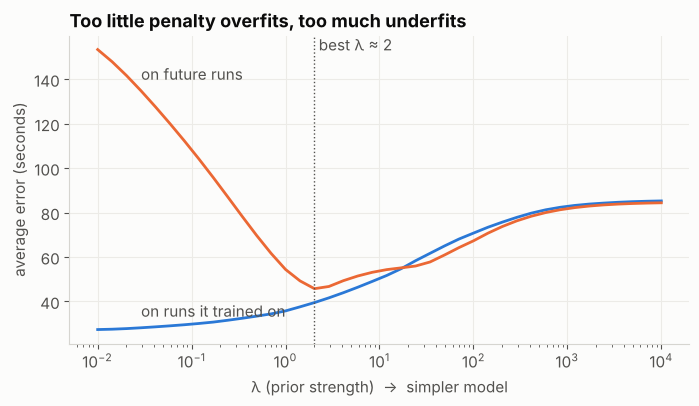

In [8]:
from sklearn.model_selection import TimeSeriesSplit

lams = np.logspace(-2, 4, 40)
train_err, test_err = [], []
for lam_ in lams:
    tr, te = [], []
    for a, b in TimeSeriesSplit(n_splits=4).split(X):
        m = Ridge(alpha=lam_, fit_intercept=False).fit(X[a], y_c[a])
        tr.append(np.abs(m.predict(X[a]) - y_c[a]).mean())
        te.append(np.abs(m.predict(X[b]) - y_c[b]).mean())
    train_err.append(np.mean(tr)); test_err.append(np.mean(te))

best = lams[int(np.argmin(test_err))]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(lams, train_err, color=BLUE); ax.plot(lams, test_err, color=ORANGE)
ax.annotate("on runs it trained on", (lams[3], train_err[3]), xytext=(0, 8), textcoords="offset points", color=INK2)
ax.annotate("on future runs", (lams[3], test_err[3]), xytext=(0, 8), textcoords="offset points", color=INK2)
ax.axvline(best, color=INK2, ls=":", lw=1)
ax.text(best, ax.get_ylim()[1], f" best λ ≈ {best:.0f}", color=INK2, va="top")
ax.set(xscale="log", title="Too little penalty overfits, too much underfits",
       xlabel="λ (prior strength)  →  simpler model", ylabel="average error (seconds)")
plt.show()

**✏️ Exercise 4 (in the app).** Open `running-coach/index.html`, find `PRIOR_SD`. The 5th number is the prior width for sleep (12 s). If you make it `2`, what happens to "what I've learned about you" after a few 5Ks? And with `200`?

<details><summary>▶ Answer</summary>

`2`: it keeps saying ~8 s per hour no matter what your data say (strong prior, big λ). `200`: it jumps to whatever your few races say, even if that's noise (weak prior, overfitting). 12 is a middle ground for a model that will only ever see a handful of races.
</details>

---
### 🎯 The 5 lines to remember
1. **Bayes:** posterior ∝ likelihood × prior. Precisions add.
2. **Bayesian regression:** the same, for weights; you get weights **and** uncertainty.
3. **Ridge** = Gaussian prior at 0 = L2 = shrink. $w=(X^\top X+\lambda I)^{-1}X^\top y$, $\lambda=\sigma^2/\tau^2$.
4. **Lasso** = Laplace prior = L1 = some weights exactly 0 = feature selection.
5. **λ** = prior strength = bias–variance dial. Choose it with cross-validation.